# LeetCode #1013: Partition Array Into Three Parts With Equal Sum

https://leetcode.com/problems/partition-array-into-three-parts-with-equal-sum/

## Comparison of Approaches

| Approach | Time Complexity | Space Complexity |
| :--- | :--- | :--- |
| **Brute Force** | $O(n^2)$ | $O(1)$ |
| **Optimal: Linear Scan ★** | $O(n)$ | $O(1)$ |

---

## Understanding the Methods

### Brute Force
Try every pair of partition indices $(i, j)$ and check whether the three parts have equal sums. This is $O(n^2)$ due to the nested loops over all split points.

### Optimal: Linear Scan ★
Compute the total sum; if it is not divisible by 3 return false immediately. Then scan left to right accumulating a running sum, incrementing a partition counter each time the running sum reaches a multiple of `total/3`. If we find at least 3 partitions before exhausting the array the answer is true.

**Constraints:**
* $3 \leq arr.length \leq 5 \times 10^4$
* $-10^4 \leq arr[i] \leq 10^4$


## Solutions

### C#


In [ ]:
public bool CanThreePartsEqualSum(int[] arr) {
    int total = 0;
    foreach (int x in arr) total += x;
    // If total is not divisible by 3, equal partition is impossible
    if (total % 3 != 0) return false;
    int target = total / 3, running = 0, parts = 0;
    foreach (int x in arr) {
        running += x;
        // Each time the running sum hits the target, a valid partition boundary is found
        if (running == target) { parts++; running = 0; }
    }
    return parts >= 3;
}


### Python


In [ ]:
def can_three_parts_equal_sum(arr: list[int]) -> bool:
    total = sum(arr)
    # Uneven total cannot be split into three equal integer parts
    if total % 3 != 0:
        return False
    target, running, parts = total // 3, 0, 0
    for x in arr:
        running += x
        # Each boundary resets the accumulator for the next partition
        if running == target:
            parts += 1
            running = 0
    return parts >= 3


### Go


In [ ]:
func canThreePartsEqualSum(arr []int) bool {
    total := 0
    for _, x := range arr {
        total += x
    }
    // Non-divisible total cannot produce three equal partitions
    if total%3 != 0 {
        return false
    }
    target, running, parts := total/3, 0, 0
    for _, x := range arr {
        running += x
        // Reset accumulator each time a partition boundary is crossed
        if running == target {
            parts++
            running = 0
        }
    }
    return parts >= 3
}


### Rust


In [ ]:
pub fn can_three_parts_equal_sum(arr: Vec<i32>) -> bool {
    let total: i32 = arr.iter().sum();
    // Early exit if total is not evenly divisible by three
    if total % 3 != 0 {
        return false;
    }
    let target = total / 3;
    let mut running = 0;
    let mut parts = 0;
    for &x in &arr {
        running += x;
        // Each hit of the target marks a valid partition cut
        if running == target {
            parts += 1;
            running = 0;
        }
    }
    parts >= 3
}


## Example Scenarios

### 1. Common Case — Three Equal Thirds
**Input:** `arr = [0, 2, 1, -6, 6, -7, 9, 1, 2, 0, 1]`

Total is 9, so the target per part is 3. The running sum reaches 3 at index 2 (part 1), resets and reaches 3 again at index 7 (part 2), then a third time at index 10. `parts = 3` → **true**, i.e. $[0,2,1] \mid [-6,6,-7,9,1] \mid [2,0,1]$, each summing to 3.

### 2. Slightly Complex — Cuts in Uneven Places
**Input:** `arr = [3, 3, 6, 5, -2, 2, 5, 1, -9, 4]`

Total is 18, target 6. The cuts land at index 1 ($3+3$), index 2 ($6$ on its own) and index 9 ($5-2+2+5+1-9+4 = 6$), so the pieces have lengths 2, 1 and 7. `parts = 3` → **true**. Equal sums say nothing about equal lengths.

### 3. Edge Case: Time Factor — Target Zero, Many Resets
**Input:** `arr = [1, -1, 1, -1, 1, -1, 1, -1, 0]`

Total is 0, so the target is 0 too and the accumulator snaps back five times (indices 1, 3, 5, 7, 8). `parts = 5 \ge 3` → **true**. The extra resets cost nothing: the scan is still one pass, $O(n)$, and never revisits an element — unlike the $O(n^2)$ brute force over split pairs.

### 4. Edge Case: Space Factor — Full Scan, No Cut Ever Found
**Input:** `arr = [1, 2, 3]`

Total is 6, target 2. Running sums are 1, 3, 6 — none equals 2, so `parts = 0` → **false** (indeed $[1] \mid [2] \mid [3]$ gives 1, 2, 3). The loop still walks the whole array while holding only three scalars — `total`, `running`, `parts` — so space stays $O(1)$ even at $n = 5 \times 10^4$.

### 5. Almost-Impossible but Plausible — Extreme Values That Cancel
**Input:** `arr = [-10000, 5000, 5000, -10000, 5000, 5000, -10000, 5000, 5000]`

Every element sits at the $\pm 10^4$ constraint edge, the total is 0 and the target is 0. Each trio cancels, so cuts land at indices 2, 5 and 8 → **true**. Note the accumulator stays within $\pm 10^4$ here, and even the worst legal input tops out at $5 \times 10^4 \times 10^4 = 5 \times 10^8$ — comfortably inside 32-bit range, so no overflow guard is needed.

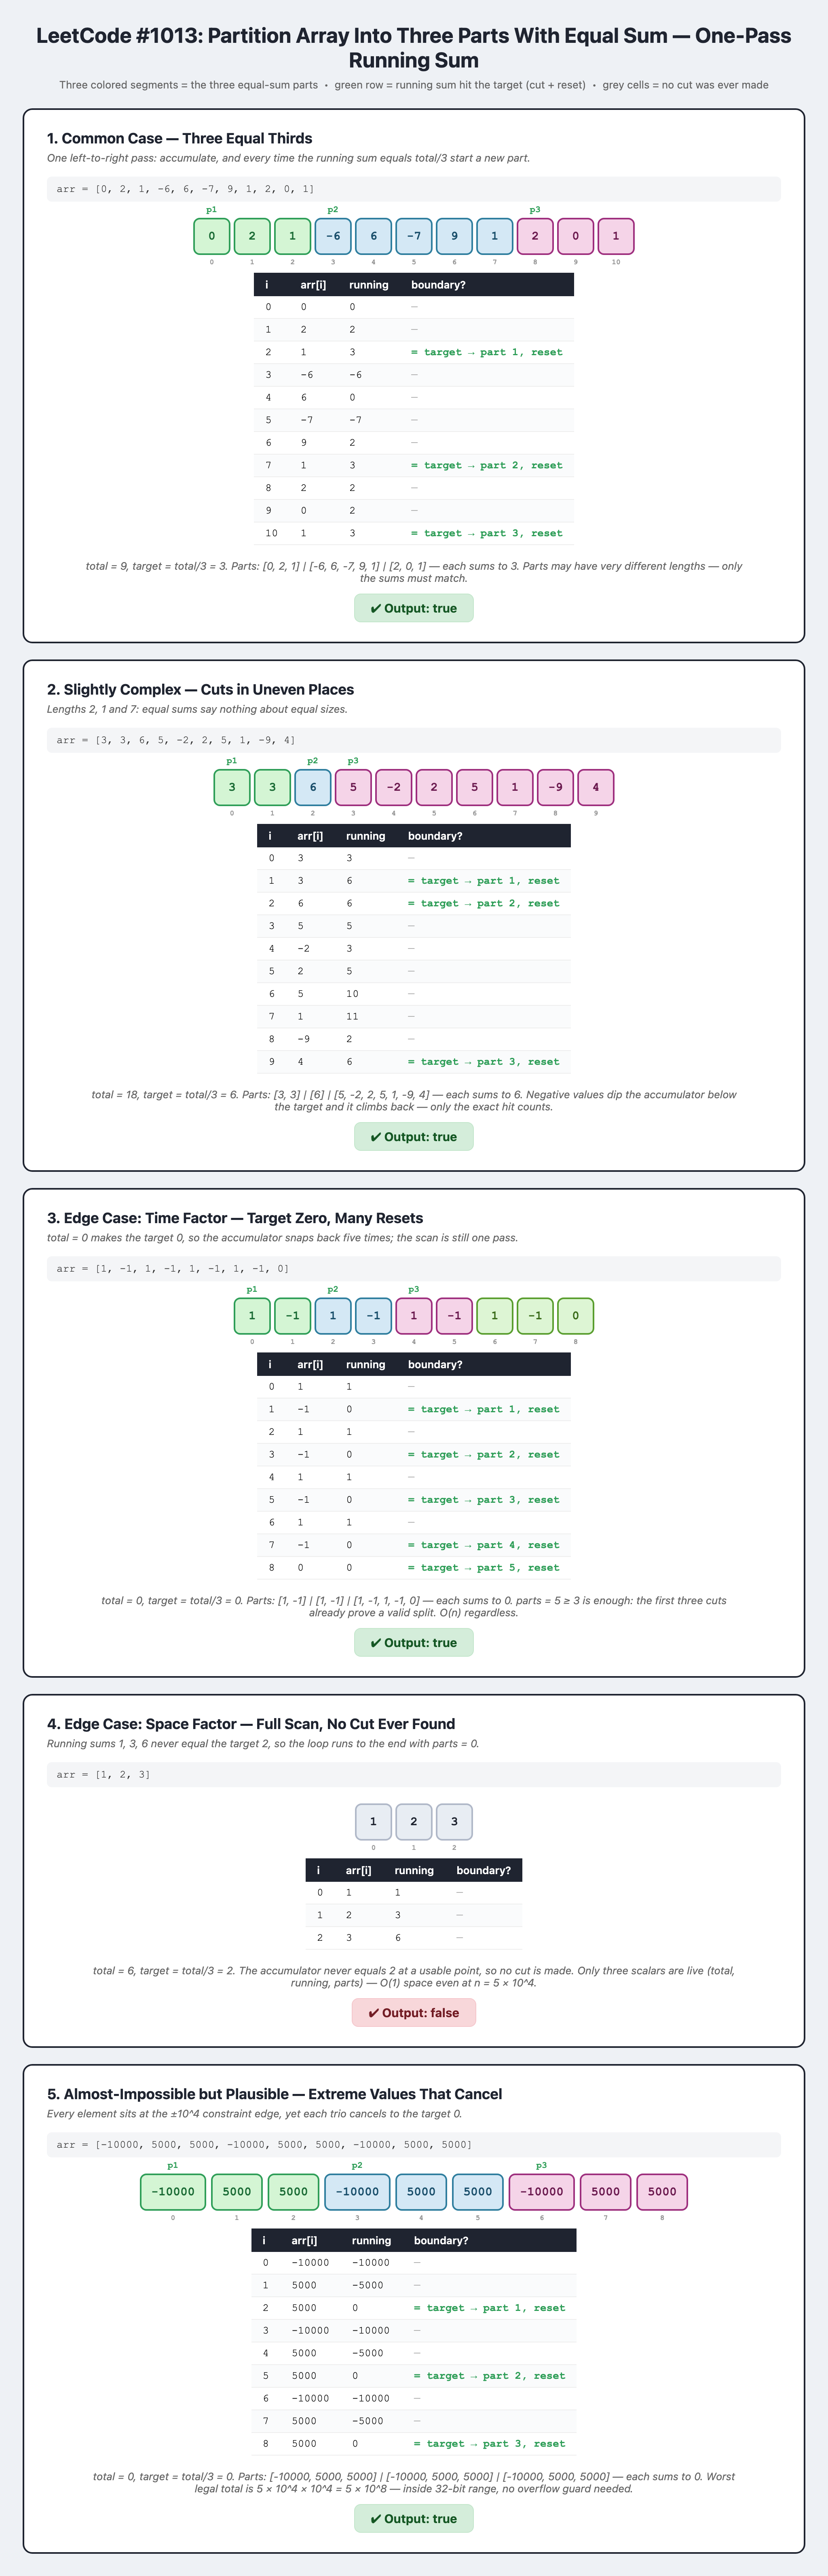